In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("titanic.csv")
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [11]:
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [13]:
from sklearn.impute import KNNImputer

# -----------------------------
# Encode Embarked
# S = Southampton
# C = Cherbourg
# Q = Queenstown
# -----------------------------
df["Embarked"] = df["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

# -----------------------------
# Fill missing values in Age using KNN
# -----------------------------
imputer = KNNImputer(n_neighbors=5)

df[["Age"]] = imputer.fit_transform(df[["Age"]])

# -----------------------------
# Fill missing values in Embarked using Median
# -----------------------------
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].median())

# -----------------------------
# Fill missing values in Cabin
# -----------------------------
df["Cabin"] = df["Cabin"].fillna("Unknown")

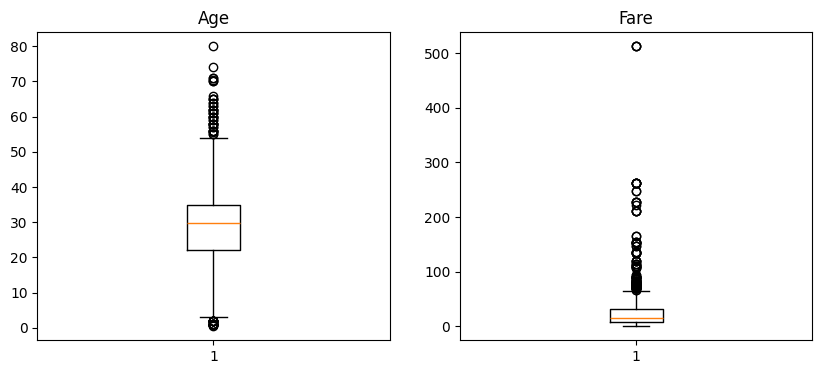

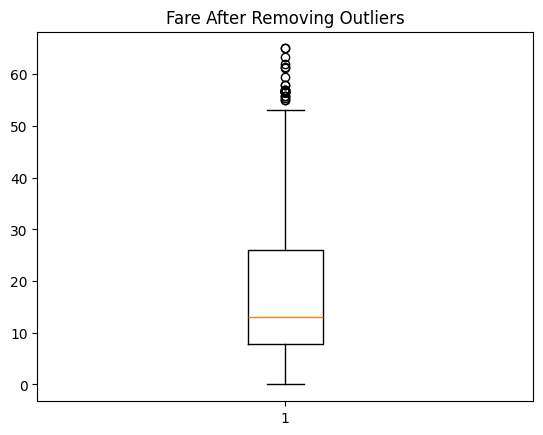

Original rows: 891
Rows after removing outliers: 775
Rows removed: 116


In [14]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.boxplot(df["Age"])
plt.title("Age")

plt.subplot(1,2,2)
plt.boxplot(df["Fare"])
plt.title("Fare")

plt.show()

# Calculate Q1 and Q3
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Remove outliers
df = df[(df["Fare"] >= lower) & (df["Fare"] <= upper)]

plt.boxplot(df["Fare"])
plt.title("Fare After Removing Outliers")
plt.show()

print("Original rows:", 891)
print("Rows after removing outliers:", len(df))
print("Rows removed:", 891 - len(df))

In [15]:
from sklearn.preprocessing import MinMaxScaler

# Create scaler
scaler = MinMaxScaler()

# Normalize Age and Fare
df[["Age", "Fare"]] = scaler.fit_transform(df[["Age", "Fare"]])

df[["Age", "Fare"]].head()

,Age,Fare
0,0.271174,0.111538
2,0.321438,0.121923
3,0.434531,0.816923
4,0.434531,0.123846
5,0.367921,0.130128


In [16]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler object
scaler = StandardScaler()

# Standardize Age and Fare
df[["Age", "Fare"]] = scaler.fit_transform(df[["Age", "Fare"]])

df[["Age", "Fare"]].head()

,Age,Fare
0,-0.556219,-0.779117
2,-0.243027,-0.729373
3,0.461654,2.599828
4,0.461654,-0.720161
5,0.046606,-0.690071


In [17]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder object
encoder = LabelEncoder()

# Encode Sex
df["Sex"] = encoder.fit_transform(df["Sex"])

# Encode Cabin
df["Cabin"] = encoder.fit_transform(df["Cabin"])

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,-0.556219,1,0,A/5 21171,-0.779117,87,NaN
2,3,1,3,"Heikkinen, Miss. Laina",0,-0.243027,0,0,STON/O2. 3101282,-0.729373,87,NaN
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.461654,1,0,113803,2.599828,35,NaN
4,5,0,3,"Allen, Mr. William Henry",1,0.461654,0,0,373450,-0.720161,87,NaN
5,6,0,3,"Moran, Mr. James",1,0.046606,0,0,330877,-0.690071,87,NaN


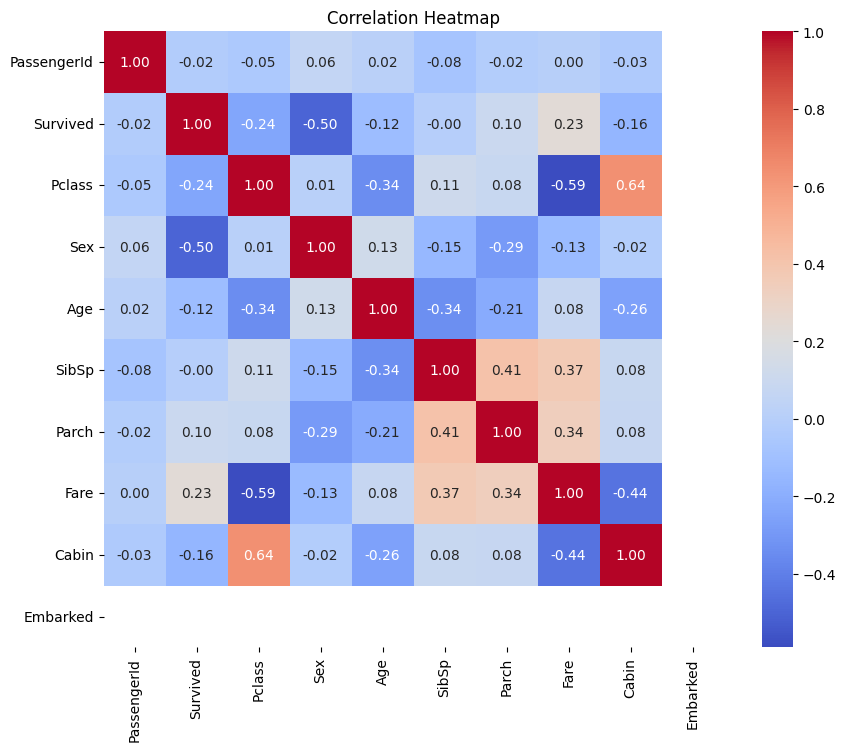

In [18]:
# Calculate correlation matrix
corr = df.corr(numeric_only=True)

# Plot heatmap
plt.figure(figsize=(10,8))

sns.heatmap(corr,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()